# 02 · Modelo de predicción — FilmAnalytics

**Objetivo:** predecir si una película será un éxito comercial *antes de su estreno*, usando solo
datos conocidos en ese momento (año, presupuesto, género, país, idioma y compañía).

- **Entrada:** `data/movies_clean.csv` (generado en `01_limpieza.ipynb`)
- **Salida:** `ml/modelo.pkl`, que usa la página web para hacer predicciones

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve,
                             roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score)

data_movies = pd.read_csv("../data/movies_clean.csv")
print(data_movies.shape)
data_movies.head()

(7046, 13)


,id,title,vote_average,vote_count,revenue,budget,original_language,year,genre_main,country_main,company_main,popularity_log,target
0,238,The Godfather,8.707,18677,245066411,6000000,en,1972,Drama,United States of America,Paramount,5.071718,1
1,278,The Shawshank Redemption,8.702,24649,28341469,25000000,en,1994,Drama,United States of America,Independiente,4.817131,0
2,240,The Godfather Part II,8.591,11293,102600000,13000000,en,1974,Drama,United States of America,Paramount,4.185905,1
3,424,Schindler's List,8.573,14594,321365567,22000000,en,1993,Drama,United States of America,Amblin Entertainment,4.190927,1
4,19404,Dilwale Dulhania Le Jayenge,8.552,4256,100000000,13200000,hi,1995,Comedy,India,Independiente,3.543131,1


## 1. Variables del modelo
Uso solo variables que se conocen **antes del estreno**. Por eso dejo fuera `vote_average`,
`vote_count` y `popularity_log`: se generan después de que la película sale, y usarlas sería
"hacer trampa" (*data leakage*).

**Objetivo (`target`):** 1 si el ingreso supera la mediana (≈ $30.2 M), 0 si no. Las clases están
balanceadas 50/50.

In [2]:
features_num = ['year', 'budget']
features_cat = ['genre_main', 'country_main', 'original_language', 'company_main']
features = features_num + features_cat

data_movies['target'].value_counts()

target
1    3523
0    3523
Name: count, dtype: int64

## 2. Exploración rápida
Antes de modelar, reviso cómo se relacionan el presupuesto y el género con el éxito.

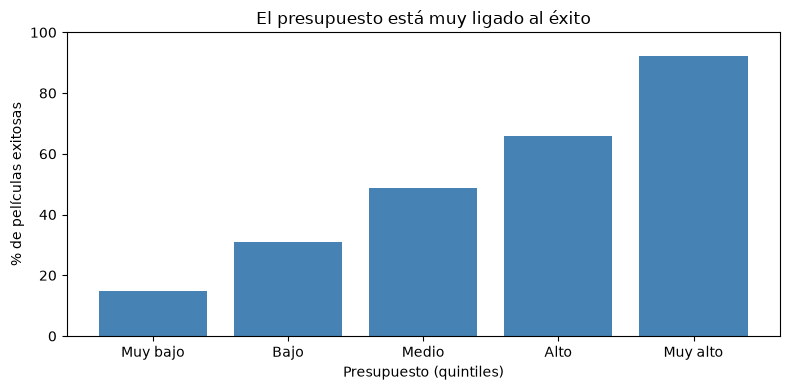

In [3]:
tasa_budget = data_movies.groupby(pd.qcut(data_movies['budget'], 5), observed=True)['target'].mean()
etiquetas = ['Muy bajo', 'Bajo', 'Medio', 'Alto', 'Muy alto']

plt.figure(figsize=(8, 4))
plt.bar(etiquetas, tasa_budget.values * 100, color='steelblue')
plt.ylabel('% de películas exitosas')
plt.xlabel('Presupuesto (quintiles)')
plt.title('El presupuesto está muy ligado al éxito')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

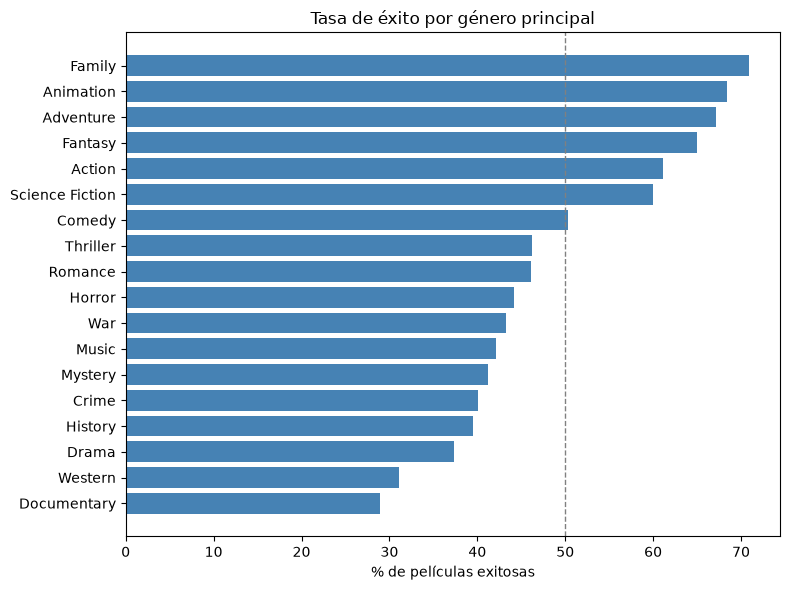

In [4]:
tasa_genero = data_movies.groupby('genre_main')['target'].mean().sort_values() * 100

plt.figure(figsize=(8, 6))
plt.barh(tasa_genero.index, tasa_genero.values, color='steelblue')
plt.axvline(50, color='gray', linestyle='--', linewidth=1)
plt.xlabel('% de películas exitosas')
plt.title('Tasa de éxito por género principal')
plt.tight_layout()
plt.show()

## 3. Modelo original (baseline)
Regresión logística con las categorías codificadas con `LabelEncoder`. Es el modelo de la primera
versión del proyecto; lo reproduzco tal cual para tener un punto de comparación.

In [5]:
data_encoded = data_movies.copy()
le = {}
for col in features_cat:
    le[col] = LabelEncoder()
    data_encoded[col] = le[col].fit_transform(data_movies[col])

X = data_encoded[features]
y = data_encoded['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_test = X_train.copy(), X_test.copy()

scaler = StandardScaler()
X_train[features_num] = scaler.fit_transform(X_train[features_num])
X_test[features_num] = scaler.transform(X_test[features_num])

modelo_base = LogisticRegression(max_iter=1000, random_state=42)
modelo_base.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

### Evaluación
**Corrección importante:** en la versión original, el AUC se calculaba con `y_pred` (predicciones
ya redondeadas a 0/1). La curva ROC necesita las **probabilidades** (`y_prob`), porque evalúa el
modelo en todos los umbrales posibles, no solo en 0.5.

In [6]:
y_pred_base = modelo_base.predict(X_test)
y_prob_base = modelo_base.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_base))
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_base))

print(f"\nAUC con y_pred (cálculo original, incorrecto): {roc_auc_score(y_test, y_pred_base):.3f}")
print(f"AUC con y_prob (cálculo correcto):            {roc_auc_score(y_test, y_prob_base):.3f}")

              precision    recall  f1-score   support

           0       0.75      0.83      0.79       731
           1       0.80      0.69      0.74       679

    accuracy                           0.77      1410
   macro avg       0.77      0.76      0.76      1410
weighted avg       0.77      0.77      0.77      1410

Matriz de confusión:
[[610 121]
 [208 471]]

AUC con y_pred (cálculo original, incorrecto): 0.764
AUC con y_prob (cálculo correcto):            0.851


In [7]:
def resumir(nombre, y_true, y_pred, y_prob):
    return {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'AUC': roc_auc_score(y_true, y_prob),
    }

resultados = [resumir('Original (LabelEncoder)', y_test, y_pred_base, y_prob_base)]
pd.DataFrame(resultados).round(3)

,Modelo,Accuracy,Precision,Recall,F1,AUC
0,Original (LabelEncoder),0.767,0.796,0.694,0.741,0.851


In [8]:
coef_base = pd.DataFrame({'Variable': features, 'Coeficiente': modelo_base.coef_[0]})
coef_base.sort_values('Coeficiente', key=abs, ascending=False)

,Variable,Coeficiente
1,budget,2.373565
5,company_main,0.029831
0,year,0.022658
3,country_main,0.012485
4,original_language,0.011663
2,genre_main,-0.003529


### ¿Qué nos dice el modelo original?
- Calculado correctamente (con probabilidades), el AUC es **0.851**. Con el cálculo original
  (con `y_pred`) salía **0.764** en estos mismos datos de prueba: el modelo era mejor de lo que
  se reportaba.
- Pero el modelo **casi solo usa el presupuesto** (coeficiente ≈ 2.4); las variables categóricas
  pesan cerca de 0.
- Esto contradice la exploración: el género sí cambia la tasa de éxito. El problema es que
  `LabelEncoder` convierte categorías en números con un orden artificial (Action = 0, Comedy = 1…),
  que una regresión logística no puede interpretar bien.

**Siguiente paso:** codificar las categorías con `OneHotEncoder`.

## 4. Modelo mejorado: OneHotEncoder + Pipeline
Codifico las categorías con `OneHotEncoder`: cada categoría se vuelve una columna de 0/1, sin orden
artificial. Todo el preprocesamiento queda dentro de un `Pipeline`, así el modelo guardado incluye
la transformación y maneja categorías nuevas sin errores (`handle_unknown="ignore"`).

Uso la **misma división** de datos que el modelo original (mismo `random_state`) para que la
comparación sea justa.

In [9]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X_raw = data_movies[features]
Xr_train, Xr_test, y_train2, y_test2 = train_test_split(X_raw, y, test_size=0.2, random_state=42)
print("¿Mismo conjunto de prueba?", (y_test2.index == y_test.index).all())

prep = ColumnTransformer([
    ("num", StandardScaler(), features_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat),
])
modelo_mejorado = Pipeline([
    ("prep", prep),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
modelo_mejorado.fit(Xr_train, y_train2)

¿Mismo conjunto de prueba? True


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['year','budget','genre_main','country_main','original_language', 'company_main']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all 

In [10]:
y_pred_mej = modelo_mejorado.predict(Xr_test)
y_prob_mej = modelo_mejorado.predict_proba(Xr_test)[:, 1]

print(classification_report(y_test2, y_pred_mej))
print("Matriz de confusión:")
print(confusion_matrix(y_test2, y_pred_mej))

resultados.append(resumir('Mejorado (OneHotEncoder)', y_test2, y_pred_mej, y_prob_mej))
pd.DataFrame(resultados).round(3)

              precision    recall  f1-score   support

           0       0.75      0.81      0.78       731
           1       0.78      0.72      0.75       679

    accuracy                           0.76      1410
   macro avg       0.77      0.76      0.76      1410
weighted avg       0.77      0.76      0.76      1410

Matriz de confusión:
[[592 139]
 [193 486]]


,Modelo,Accuracy,Precision,Recall,F1,AUC
0,Original (LabelEncoder),0.767,0.796,0.694,0.741,0.851
1,Mejorado (OneHotEncoder),0.765,0.778,0.716,0.745,0.846


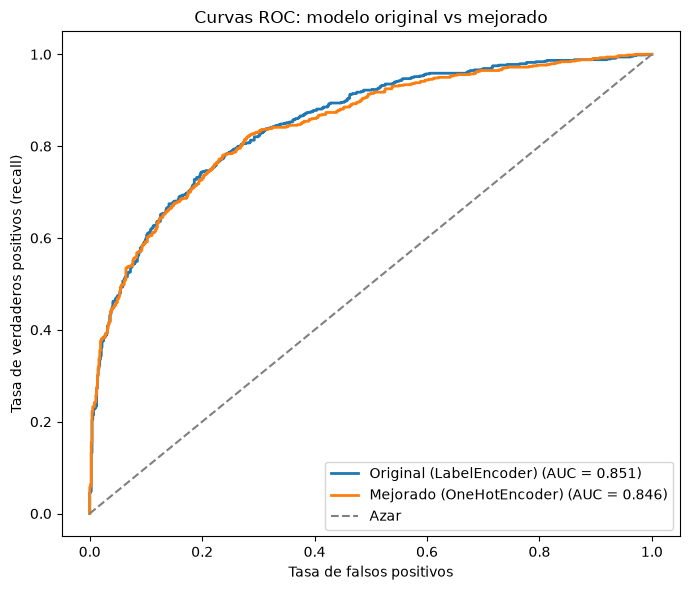

In [11]:
plt.figure(figsize=(7, 6))
for nombre, y_prob in [('Original (LabelEncoder)', y_prob_base), ('Mejorado (OneHotEncoder)', y_prob_mej)]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {roc_auc_score(y_test, y_prob):.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Azar')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curvas ROC: modelo original vs mejorado')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Comparación robusta: validación cruzada
Una sola división train/test puede variar por suerte. Con **validación cruzada de 5 partes**, entreno
y evalúo 5 veces con distintas divisiones y promedio el AUC. Agrego un modelo de referencia que
usa **solo el presupuesto**, para medir cuánto aportan las demás variables.

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def pipeline_con(encoder):
    return Pipeline([
        ("prep", ColumnTransformer([("num", StandardScaler(), features_num),
                                    ("cat", encoder, features_cat)])),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ])

candidatos = {
    'Solo presupuesto': (Pipeline([("s", StandardScaler()), ("m", LogisticRegression())]), data_movies[['budget']]),
    'Original (LabelEncoder)': (pipeline_con(OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)), X_raw),
    'Mejorado (OneHotEncoder)': (pipeline_con(OneHotEncoder(handle_unknown='ignore')), X_raw),
}

filas = []
for nombre, (modelo, X_cv) in candidatos.items():
    scores = cross_val_score(modelo, X_cv, y, cv=cv, scoring='roc_auc')
    filas.append({'Modelo': nombre, 'AUC promedio': scores.mean(), 'Desv. estándar': scores.std()})
pd.DataFrame(filas).round(3)

,Modelo,AUC promedio,Desv. estándar
0,Solo presupuesto,0.822,0.012
1,Original (LabelEncoder),0.827,0.011
2,Mejorado (OneHotEncoder),0.830,0.009


In [13]:
auc_por_particion = {}
for nombre, (modelo, X_cv) in candidatos.items():
    auc_por_particion[nombre] = cross_val_score(modelo, X_cv, y, cv=cv, scoring='roc_auc')

tabla_particiones = pd.DataFrame(auc_por_particion, index=[f'Partición {i}' for i in range(1, 6)])
tabla_particiones['Diferencia (mejorado - original)'] = (
    tabla_particiones['Mejorado (OneHotEncoder)'] - tabla_particiones['Original (LabelEncoder)'])
tabla_particiones.round(3)

,Solo presupuesto,Original (LabelEncoder),Mejorado (OneHotEncoder),Diferencia (mejorado - original)
Partición 1,0.815,0.823,0.826,0.003
Partición 2,0.831,0.836,0.834,-0.001
Partición 3,0.801,0.806,0.815,0.009
Partición 4,0.835,0.833,0.843,0.010
Partición 5,0.828,0.835,0.832,-0.003


### Conclusiones de la comparación
- El modelo mejorado **no supera de forma significativa** al original: la diferencia de AUC
  (≈ 0.003) es menor que la variación entre particiones (≈ 0.01).
- El **presupuesto por sí solo** ya logra un AUC de 0.822; las demás variables aportan muy poco.
- **Conclusión:** el límite del modelo no está en la codificación, sino en la información
  disponible. Para mejorar habría que agregar variables nuevas (mes de estreno, director,
  reparto, secuela) o redefinir el éxito.
- Aun así, **elijo el modelo mejorado** para la página: es metodológicamente correcto para
  variables sin orden, maneja categorías nuevas sin errores y todo vive en un solo Pipeline.

## 5. ¿Qué variables pesan más en el modelo mejorado?
Con OneHotEncoder, cada categoría tiene su propio coeficiente. Un coeficiente positivo sube la
probabilidad de éxito y uno negativo la baja, **a igual presupuesto y año**.

Variables numéricas:
num__year      0.053
num__budget    2.351
dtype: float64


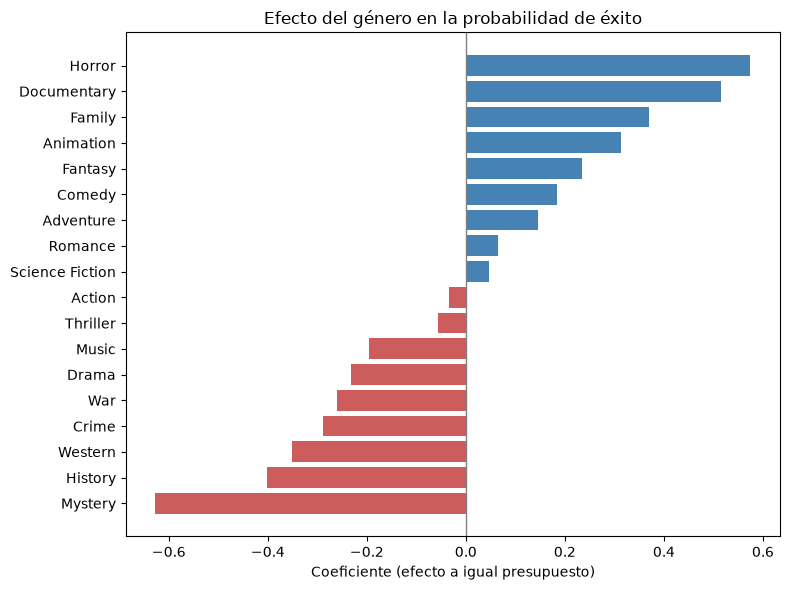

In [14]:
nombres = modelo_mejorado.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(modelo_mejorado.named_steps['model'].coef_[0], index=nombres)

print("Variables numéricas:")
print(coefs[['num__year', 'num__budget']].round(3))

coef_genero = coefs[coefs.index.str.startswith('cat__genre_main_')]
coef_genero.index = coef_genero.index.str.replace('cat__genre_main_', '')
coef_genero = coef_genero.sort_values()

plt.figure(figsize=(8, 6))
plt.barh(coef_genero.index, coef_genero.values,
         color=['indianred' if v < 0 else 'steelblue' for v in coef_genero.values])
plt.axvline(0, color='gray', linewidth=1)
plt.xlabel('Coeficiente (efecto a igual presupuesto)')
plt.title('Efecto del género en la probabilidad de éxito')
plt.tight_layout()
plt.show()

### Interpretación
- El **presupuesto** domina el modelo (coeficiente ≈ 2.35); el año casi no influye (≈ 0.05).
- A igual presupuesto, **Horror, Documentary y Family** rinden más de lo esperado, y **Mystery,
  History y Western**, menos.
- Esto difiere de la exploración inicial (donde Documentary tenía baja tasa de éxito) porque
  aquí el efecto está **controlado por presupuesto**: los documentales recaudan poco en total,
  pero mucho en relación con lo que cuestan.
- *Precaución:* los coeficientes de países o idiomas con pocas películas son poco confiables.

## 6. Conclusiones y próximos pasos
**Conclusiones**
- El modelo alcanza un AUC ≈ 0.83 en validación cruzada: distingue bien entre películas exitosas
  y no exitosas antes de su estreno.
- Corregir el cálculo del AUC mostró que el modelo original era mejor de lo reportado (0.764 → 0.851).
- Cambiar a OneHotEncoder no mejoró significativamente las métricas: el presupuesto concentra casi
  toda la información disponible.

**Próximos pasos**
- Agregar variables nuevas: mes de estreno, director, reparto, si es secuela.
- Ajustar los ingresos por inflación y probar definir el éxito como retorno sobre inversión
  (ingreso / presupuesto).
- Probar modelos no lineales (por ejemplo, Random Forest) con validación cruzada.

## 7. Modelo final
Una vez evaluado, reentreno el modelo mejorado con **todos los datos** (más información para
las predicciones reales) y lo guardo para la página web.

In [15]:
import pickle

modelo_final = Pipeline([
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), features_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat),
    ])),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
modelo_final.fit(X_raw, y)

with open("../ml/modelo.pkl", "wb") as f:
    pickle.dump(modelo_final, f)

print("Modelo guardado en ml/modelo.pkl")

Modelo guardado en ml/modelo.pkl
